## Part A

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

# 1. Load dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df['target_name'] = df['target'].map({0: 'Malignant', 1: 'Benign'})


In [2]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,target_name
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


In [28]:
# 2. Compute summary statistics
summary_stats = df.describe().T
summary_stats['median'] = df.median(numeric_only=True)
print("--- Summary Statistics ---")
print(summary_stats[['mean', 'std', 'min', '50%', 'median', 'max']].head())


--- Summary Statistics ---
                       mean         std        min        50%     median  \
mean radius       14.127292    3.524049    6.98100   13.37000   13.37000   
mean texture      19.289649    4.301036    9.71000   18.84000   18.84000   
mean perimeter    91.969033   24.298981   43.79000   86.24000   86.24000   
mean area        654.889104  351.914129  143.50000  551.10000  551.10000   
mean smoothness    0.096360    0.014064    0.05263    0.09587    0.09587   

                       max  
mean radius        28.1100  
mean texture       39.2800  
mean perimeter    188.5000  
mean area        2501.0000  
mean smoothness     0.1634  


In [11]:

# 3. Check for missing values, duplicates, and outliers
print(f"\nMissing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")

# Handle outliers using Interquartile Range (IQR) capping
for col in data.feature_names:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = np.clip(df[col], Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)



Missing Values: 0
Duplicate Rows: 0


C:\Users\hpCND\AppData\Local\Temp\ipykernel_30532\971591747.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target_name', data=df, ax=axes[0, 0], palette='Set2')


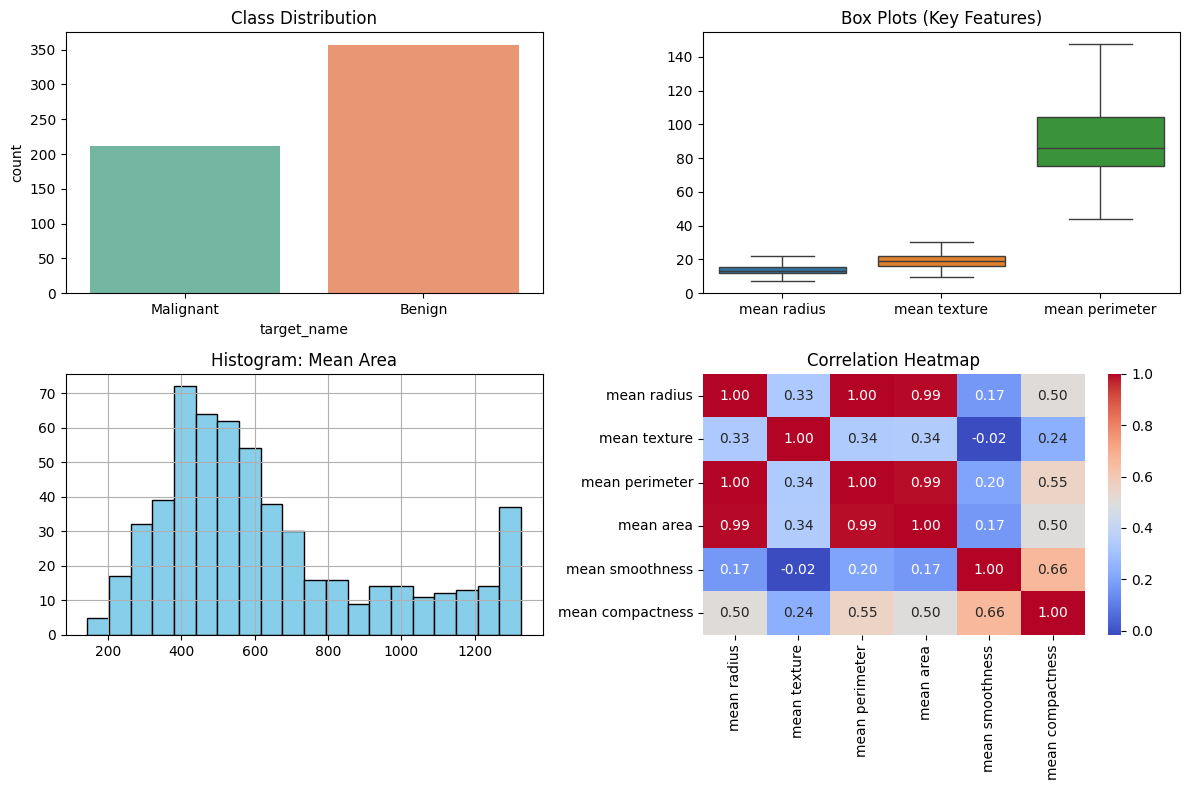

In [12]:

# 4. Data Visualizations
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Class Distribution
sns.countplot(x='target_name', data=df, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title("Class Distribution")

# Box Plots for Key Features
sns.boxplot(data=df[['mean radius', 'mean texture', 'mean perimeter']], ax=axes[0, 1])
axes[0, 1].set_title("Box Plots (Key Features)")

# Histogram for Key Feature
df['mean area'].hist(ax=axes[1, 0], bins=20, color='skyblue', edgecolor='black')
axes[1, 0].set_title("Histogram: Mean Area")

# Correlation Heatmap
sns.heatmap(df[data.feature_names[:6]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## Part B

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Encode target variable (0 = Malignant, 1 = Benign)[cite: 1]
X = df[data.feature_names]
y = df['target']

# 2. Split data: 80/20 train/test split with stratified sampling[cite: 1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)




In [ ]:
# 3. Standardize features for scale sensitivity[cite: 1]
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Part C

Accuracy: 0.9825

Classification Report (0 = Malignant, 1 = Benign):
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



c:\Users\hpCND\anaconda3\envs\ai\lib\site-packages\sklearn\utils\_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


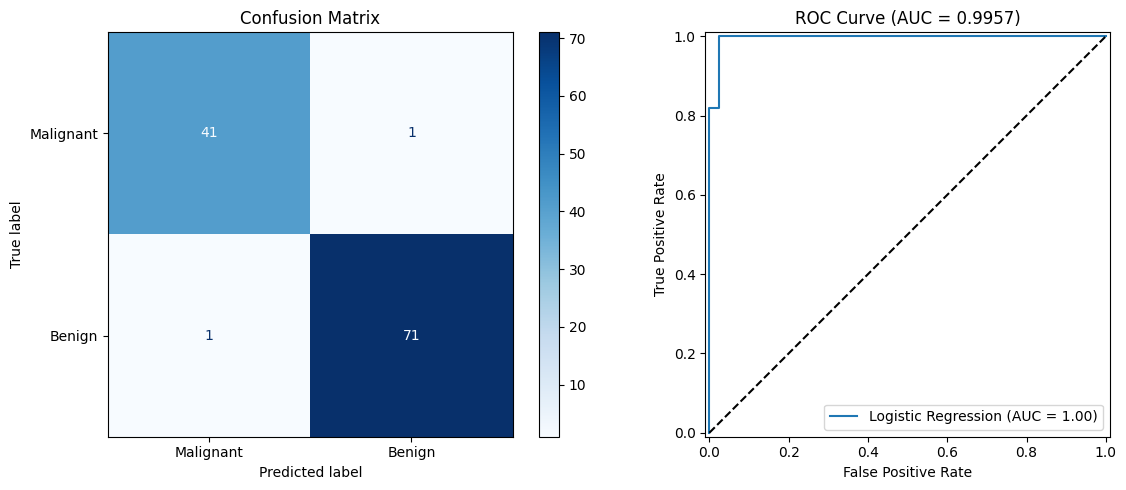

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay, roc_curve, auc, RocCurveDisplay


# 1. Train Logistic Regression Model[cite: 1]
model = LogisticRegression(random_state=42, max_iter=1000)
model.fit(X_train_scaled, y_train)

# Model Predictions
y_pred = model.predict(X_test_scaled)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]



In [15]:
# 2. Evaluation Metrics[cite: 1]
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report (0 = Malignant, 1 = Benign):")
print(classification_report(y_test, y_pred, target_names=['Malignant', 'Benign']))



Accuracy: 0.9825

Classification Report (0 = Malignant, 1 = Benign):
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



c:\Users\hpCND\anaconda3\envs\ai\lib\site-packages\sklearn\utils\_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


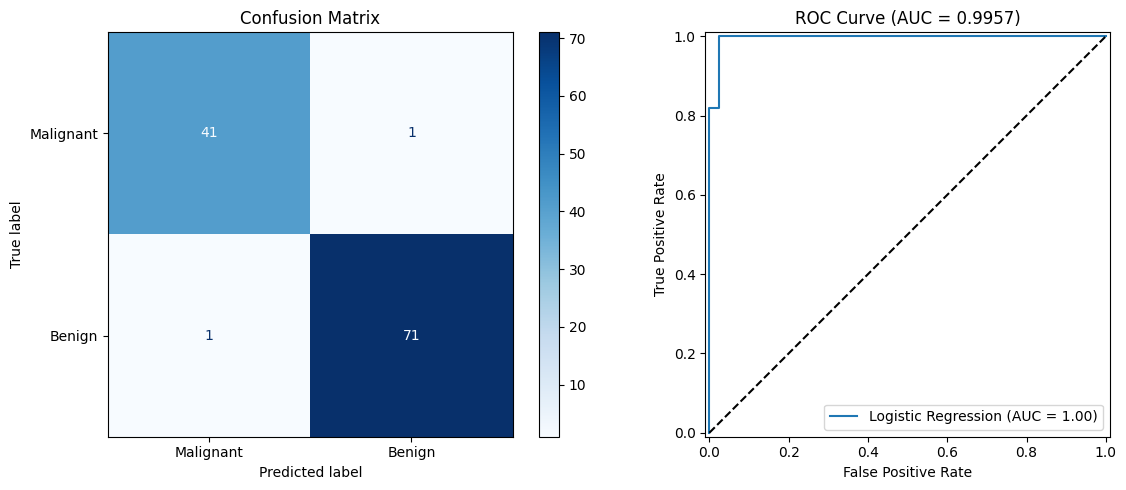

In [16]:
# Visualizing Confusion Matrix and ROC Curve[cite: 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Malignant', 'Benign']).plot(ax=axes[0], cmap='Blues')
axes[0].set_title("Confusion Matrix")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)
RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc, estimator_name='Logistic Regression').plot(ax=axes[1])

axes[1].plot([0, 1], [0, 1], 'k--', label='Baseline (AUC = 0.50)')
axes[1].set_title(f"ROC Curve (AUC = {roc_auc:.4f})")

plt.tight_layout()
plt.show()